# 2023年Java大厂面试｜05：微服务、分布式事务、幂等与任务调度

> 学习目标：讲清服务怎样找到并调用另一个服务，怎样控制故障与流量，怎样观察跨服务请求，以及多服务写入、重复请求和分片任务如何保证业务结果正确。

**主要依据：** `5.2023版Java面试教程/05-微服务篇/PPT/05-微服务篇.pptx`，53页。已读取全部文字、组合形状、表格与备注，查看21张去重嵌入图片总览，单独检查Feign降级、Nginx限流、Gateway限流、XXL-JOB配置及失败告警截图。第53页为空白。

**配套阅读：** 飞书《微服务篇》的18组正文问答；网盘`资料/skywalking/讲义/项目链路追踪.md`的预览文字与源码末尾。链路追踪讲义采用SkyWalking **8.2.0**，邮件模块示例出现Boot **2.1.3.RELEASE**。其图片相对路径在网盘预览中未加载成功，因此没有将这些图内的配置视为已核验内容。源码最后停在“10分钟内服务成功率低于80%超过2次，”这句话，后续告警实验步骤缺失。

视频目录共11节，只核对标题，未观看或转写。配套PDF、assets图片目录与运行资料未逐项读取。讲义下载尝试未取得文件，曾出现“验证码已过期”，但网页正文可读。本篇以实际读到的PPT、在线问答和Markdown文字为依据。

课件使用Ribbon、Hystrix等旧体系。“课件要点”保留课程问题与机制；“补充说明”“修正”解释适用条件、旧版本区别和示例缺陷。补充内容未逐项联网核验最新版本。配置、Java、SQL与Lua均为学习片段，**未编译或执行**，未部署项目、连接数据库、发告警邮件或进行压测。

### 阅读路线

- 1～6：Spring Cloud组件、注册发现、Nacos/Eureka、负载均衡与自定义规则
- 7～9：服务雪崩、降级和断路器
- 10～13：SkyWalking架构、接入、指标与告警
- 14～18：限流层次、算法、Nginx与Gateway
- 19～25：CAP/BASE、Seata的XA/AT/TCC、可靠消息与最终一致性
- 26～29：幂等、数据库约束、Token、分布式锁
- 30～32：XXL-JOB路由、失败处理和分片
- 33～35：综合案例、面试自测、练习、勘误与来源覆盖

课程里的“我们项目”、峰值QPS、服务器IP、邮箱和截图均属于教学案例，不能直接写成自己的真实工作经历。


## 1. Spring Cloud组件与一次请求的分工

**课件第4～5页、在线问答1：** 早期常用组件组合是Eureka、Ribbon、Feign、Hystrix、Zuul；课程还将Gateway列为网关选项。Alibaba示例采用Nacos、Ribbon、Feign、Sentinel、Gateway。

| 职责 | 课程组件 | 补充说明与版本边界 |
|---|---|---|
| 服务注册与发现 | Eureka、Nacos | 提供实例列表和健康信息，注册中心通常不转发业务请求 |
| 配置管理 | Nacos | 配置中心管理配置，服务发现管理实例，两个功能应分别分析 |
| 客户端负载均衡 | Ribbon | 较新Spring Cloud项目通常采用Spring Cloud LoadBalancer，须核对依赖 |
| 声明式HTTP调用 | Feign/OpenFeign | 把接口调用转换成HTTP请求，实际HTTP客户端、负载均衡与熔断来自集成配置 |
| 服务保护 | Hystrix、Sentinel | Hystrix属于旧体系；也可通过Spring Cloud CircuitBreaker集成如Resilience4j等实现 |
| API网关 | Zuul、Gateway | 承担路由和过滤等入口职责，具体Web模型及配置路径与版本有关 |
| 链路监控 | SkyWalking | 还原调用链并采集相关指标，不代替业务事务或鉴权 |

“五大组件”是历史教材的常见归纳，不能据此断言所有Spring Cloud项目必须同时装这五个组件，也不能把不同发行列车的版本随意混用。

**补充一次调用的典型过程：**

~~~text
客户端请求进入Gateway
Gateway匹配路由并执行认证、限流等过滤
订单服务调用Feign接口
发现客户端提供用户服务的可用实例列表
负载均衡选择一个实例
HTTP客户端发送请求，受连接/读取超时约束
断路器或降级逻辑处理失败
探针传播追踪上下文，记录各节点耗时
~~~

每次请求不一定重新访问注册中心。发现客户端通常有缓存和更新机制。调用是否经过每个保护组件，由项目实际依赖和配置决定。

**面试回答：** 先说具体组件负责什么，再说自己项目使用的版本和调用流程。Gateway、Nacos、Feign不能互相替代。


## 2. 服务注册、发现与Eureka健康检查

**课件第6～8页、在线问答2：** 服务提供者把服务名、IP、端口等注册到注册中心；消费者获取实例列表，选择实例并远程调用。Eureka示意中，`order-service`调用多个`user-service`实例中的一个。

| 阶段 | 谁执行 | 保存或使用什么 |
|---|---|---|
| 注册 | 服务实例/发现客户端 | 服务名、实例地址、端口、状态及元数据 |
| 续约/健康检查 | 客户端与注册中心 | 判断实例是否仍具备注册或服务条件 |
| 发现 | 消费方的发现客户端 | 获得目标服务实例列表并缓存 |
| 实例选择 | 客户端负载均衡器 | 按规则选出一个目标地址 |
| 请求 | HTTP/RPC客户端 | 直接向目标实例发起业务调用 |

**时间参数修正：** 课件用“30秒一次心跳、90秒没心跳剔除”说明Eureka。30秒续约间隔和90秒租约期限是常见默认配置，实际还受服务端清理周期、网络延迟、客户端缓存和自我保护影响，**不能承诺90秒时调用方一定停止访问该实例**。

**补充自我保护：** 当Eureka观察到大量续约丢失时，可能进入自我保护并暂缓失效实例的淘汰。其设计希望避免网络故障导致批量误剔除，代价是消费者可能看到陈旧实例。调用方仍需超时、熔断、失败处理和合理的重试。

注册信息存在，不代表业务接口、数据库、线程池全部健康；心跳只说明某种存活条件。业务健康检查需要覆盖真正依赖的关键资源，但也要避免过重探测拖垮系统。

**注册中心不可用的追问：** 已启动消费者可能依靠缓存继续调用已知实例；新实例注册、实例变更传播和首次发现会受影响。能继续多久、缓存如何过期，需要看具体客户端和配置。


## 3. Nacos流程与Eureka的区别

**课件第9～10页、在线问答3：** Nacos支持注册发现和配置管理。课件以拉取、缓存、变更推送、临时/非临时实例说明其工作流程。

| 比较项 | Eureka | Nacos课程模型 |
|---|---|---|
| 注册发现 | 支持 | 支持 |
| 健康检查 | 以租约续约为核心 | 临时实例侧重客户端存活上报，持久实例可由服务端探测 |
| 实例失效 | 受租约、淘汰、自我保护影响 | 临时实例可被清理；持久实例可标记不健康并保留注册信息 |
| 列表更新 | 客户端周期获取等 | 缓存结合订阅通知/推送等，协议随版本变化 |
| 配置中心 | Eureka自身主要负责注册发现 | Nacos还有配置中心功能 |
| 一致性 | 通常按AP取向描述 | 临时注册与持久注册采用不同的一致性机制，需要按模块讨论 |

课件截图通过`spring.cloud.nacos.discovery.ephemeral: false`说明非临时实例。这只是相应旧版客户端集成的配置示意，不能据此判断整个集群的所有功能都切换成同一种模式。

**修正两个常见口号：**

- “有非临时实例就把整个Nacos集群切成CP”过于粗略。通常应分别讨论临时实例的Distro/AP取向、持久实例的Raft一致性机制，以及配置管理自身的一致性路径。
- “Nacos临时实例永远每隔几秒发HTTP心跳”不适合所有版本。Nacos 1.x常见HTTP心跳与UDP通知，2.x临时实例常见gRPC长连接和连接存活机制。服务端、SDK与适配组件必须一起核对。

非临时实例保留注册信息，不代表不健康实例就该继续接流量。正常消费者应按健康状态过滤，具体查询条件与保护机制仍需确认。

**补充隔离维度：** namespace、group、service name可以组织和隔离服务；同服务实例还可有cluster、权重及元数据。调用不到服务时，应检查环境、分组、服务名、实例状态、网络和客户端版本，不能只检查IP。

**面试回答：** 两者都解决实例注册与发现；Nacos还提供配置管理和相应订阅机制，实例健康与一致性方式需结合临时/持久类型和具体版本解释。


## 4. 客户端负载均衡的完整流程

**课件第11～12、15页、在线问答4：** 课程中的Feign集成Ribbon。订单服务访问逻辑服务名，Ribbon从可用实例中选出具体地址。

~~~text
逻辑地址：http://userservice/user/1
实例列表：host-a:8081、host-b:8082
选择结果：host-a:8081
实际请求：http://host-a:8081/user/1
~~~

**补充职责划分：** 发现客户端获得和更新实例信息，负载均衡器维护/使用候选列表并作选择，HTTP客户端发送请求。课件把拉列表与选择画在同一流程中是便于理解，不代表每次选择都直接向注册中心发网络请求。

| 形式 | 典型位置 | 请求选择由谁完成 |
|---|---|---|
| 服务端负载均衡 | Nginx等代理 | 请求先经过代理，由代理选后端 |
| 客户端负载均衡 | Ribbon、Spring Cloud LoadBalancer | 调用方用实例列表自行选目标 |

“加`@LoadBalanced`就所有HTTP调用都负载均衡”也不准确。它作用于相应框架支持并由容器管理的客户端Bean及调用链，自己创建的HTTP客户端、指定固定URL或缺少负载均衡依赖，都可能绕过服务名解析。

**排查某个实例总是被调用：** 查看是否使用固定URL、是否只有一个健康实例、规则/权重是否生效、配置是否进入对应服务的子上下文，再检查请求数量和重试行为。几次请求的观察不足以证明全局流量分配规律。


## 5. Ribbon的七种负载均衡规则

**课件第13、15页、在线问答5：**

| 规则 | 核心机制 | 面试时应补的边界 |
|---|---|---|
| RoundRobinRule | 轮询实例 | 轮询的是当前候选列表，列表变更会改变顺序 |
| RandomRule | 随机选择 | 有限次请求不会保证绝对均分 |
| WeightedResponseTimeRule | 根据响应时间统计调整权重 | 更快的实例通常获得更高权重，统计和初始化有延迟 |
| BestAvailableRule | 排除熔断等不可用候选，选活动请求较少的实例 | 依赖客户端统计，不能保证全系统最空闲 |
| RetryRule | 在限制时间内重新选择 | 与HTTP重试不是同一个层次，需看委托规则及实现 |
| AvailabilityFilteringRule | 过滤被熔断或并发超过阈值的实例，再按委托轮询规则选择 | 课件“选连接数较小”容易与BestAvailable混淆 |
| ZoneAvoidanceRule | 综合区域与实例可用性筛选，再选择实例 | 不是对每一个跨区请求都作严格禁止 |

**默认规则修正：** 课件把ZoneAvoidanceRule标成默认，符合常见旧Spring Cloud Ribbon自动配置；Ribbon核心某些默认配置则使用RoundRobinRule。应说清是在什么组件集成与配置下，不能笼统说“所有Ribbon默认都一样”。

**规则选择问题：**

- 轮询容易理解，但机器规格、请求耗时和实例健康差异会导致负载不均。
- 权重能表达容量差异，但权重不能替代健康检查。
- 优先同区域通常减少跨区延迟，但当地实例不足时仍需明确跨区回退行为。
- 灰度、版本路由和租户隔离需要先筛选正确候选，再进行负载均衡，不能让随机算法承担权限隔离。

现代Spring Cloud LoadBalancer具有另一套接口与实现，这七个`IRule`类属于Ribbon体系，不能直接当作新组件的可用配置。


## 6. 自定义负载均衡：规则与作用范围

**课件第14～15页、在线问答6：** 可提供`IRule`实现或配置规则类。以下是整理后的旧Ribbon示例，未执行。

~~~java
// 旧Ribbon学习片段
@Bean
public IRule randomRule() {
    return new RandomRule();
}
~~~

~~~yaml
# 旧Ribbon：为userservice指定规则
userservice:
  ribbon:
    NFLoadBalancerRuleClassName: com.netflix.loadbalancer.RandomRule
~~~

**范围修正：** Bean是否全局影响多个客户端，与配置类放置位置、组件扫描和客户端子上下文有关。通过`@RibbonClient(name="userservice", configuration=...)`等机制配置的规则可以只针对指定客户端；将专用配置意外扫进主上下文则可能扩大作用范围。课件“Bean一定全局、配置文件一定局部”只是教学简化。

自定义规则通常要处理空列表、健康状态、选择失败及必要的统计，避免死循环和重复查询。仅为了随机选择，使用已有RandomRule即可，不必重新实现算法。

**补充新体系：** Spring Cloud LoadBalancer常见的扩展点包括`ServiceInstanceListSupplier`与`ReactorLoadBalancer<ServiceInstance>`。它们分别承担候选实例列表与选择逻辑等职责，配置方法与Ribbon不同。具体项目应按对应Spring Cloud版本写配置，不能同时照搬两套示例。

**面试回答：** 先明确调用哪个服务和希望实现什么规则，再说明扩展点、配置作用范围、健康过滤和验证方法。


## 7. 服务雪崩的传播与保护措施

**课件第16～19页、在线问答7：** 下游服务失败使整条调用链陆续失败，称为服务雪崩。课件重点讲熔断降级和限流。

**补充实际传播过程：** 下游响应变慢，上游请求长期等待，占满工作线程、连接池或排队空间。新请求继续进入，其他原本正常的接口也拿不到资源。若各层自动重试，还会进一步放大下游流量。

| 措施 | 解决的问题 | 使用边界 |
|---|---|---|
| 连接、读取、整体超时 | 防止无限等待 | 读取超时与整次请求截止时间并不完全相同 |
| 隔离/舱壁 | 一个依赖耗尽共享资源 | 限制线程、并发或连接，容量需根据业务测定 |
| 降级 | 关键路径失败时返回可接受的替代结果 | 应准确表达失败、待处理或缓存状态 |
| 熔断 | 对高失败率依赖快速失败 | 通常按依赖或资源统计，需探测恢复 |
| 限流 | 进入系统的请求超出可承受能力 | 拒绝策略和重试提示要明确 |
| 有界重试、退避与抖动 | 处理暂时性失败 | 写请求先保证幂等，避免每层都重试 |
| 缓存与削峰 | 减少同步下游压力 | 要处理缓存时效、队列堆积和一致性 |

**补充超时预算示例：** 若外层接口目标1秒，下游调用不能各自无约束重试3次、每次等1秒。应给链路划分总预算，算上本地逻辑、网络、数据库与回退时间。这是设计示例，不是课程压测结论。

熔断器Open时的“失败”可以很快返回；线程池饱和时即使下游已经恢复，也可能仍然排队。排障要同时看延迟、错误、并发、池容量和队列，不能只看某台服务是否存活。


## 8. Feign降级与业务语义

**课件第17页：** 为Feign接口指定fallback类，fallback实现同一接口，返回错误结果。

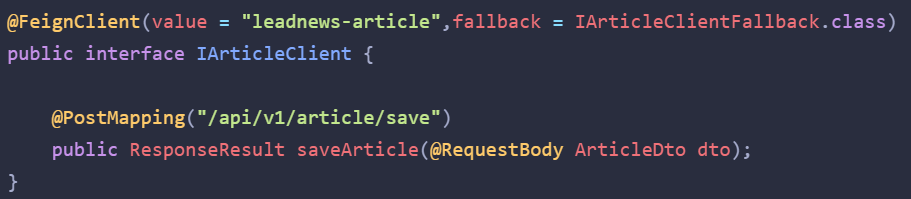

~~~java
// 课程模式的整理片段，省略DTO及结果类型，未编译/执行
@FeignClient(name = "article-service", fallback = ArticleFallback.class)
public interface ArticleClient {
    @PostMapping("/api/v1/article/save")
    ApiResult saveArticle(@RequestBody ArticleDto dto);
}

@Component
public class ArticleFallback implements ArticleClient {
    @Override
    public ApiResult saveArticle(ArticleDto dto) {
        return ApiResult.failure("文章服务暂时不可用");
    }
}
~~~

**修正：** 配置`fallback`属性并不自动证明断路器集成已启用。旧Feign+Hystrix、Feign+Sentinel和Spring Cloud CircuitBreaker的开关、依赖与异常处理方式不同。应检查实际Feign构建器、相关配置和运行验证。

降级可以返回过期缓存、减少次要功能、明确错误或异步受理状态；必须符合业务约定。例如文章保存超时，服务端可能已经提交，仅调用方没有收到结果。不能在fallback中“假装保存成功”，也不能立刻无条件重复新增。

**补充失败信息：** 需要区分限流拒绝、超时、业务异常、断路器已打开、连接失败等情况。相应集成可使用fallback factory或其他异常处理扩展获取原因，避免所有故障都变成模糊的“网络有问题”。

**面试回答：** 描述哪个下游在什么条件下触发回退，回退返回什么业务状态，如何告警，以及写操作结果未知时如何查询或凭同一幂等键重试。


## 9. 熔断器的三种状态与Hystrix参数

**课件第18～19页：** Closed、Open、Half-Open三个状态。

| 状态 | 请求行为 | 转移条件 |
|---|---|---|
| Closed，关闭 | 正常调用并统计成功/失败 | 请求量达到最低条件，失败比例超过阈值等 |
| Open，打开 | 快速失败，通常进入回退 | 等待恢复探测的时间窗口 |
| Half-Open，半开 | 放行受限数量的探测请求 | 探测成功则恢复，失败则继续打开 |

**Hystrix旧实现说明：** 课件“10秒失败率50%、5秒重试”对应常见默认值，但遗漏最低请求量条件。常见相关默认配置是：

~~~properties
# 旧Hystrix默认值学习记录，具体工程需核对
metrics.rollingStats.timeInMilliseconds=10000
circuitBreaker.requestVolumeThreshold=20
circuitBreaker.errorThresholdPercentage=50
circuitBreaker.sleepWindowInMilliseconds=5000
~~~

意思是滚动统计窗口内满足至少20次请求等条件，错误比例达到阈值才可能打开。5秒是打开后的探测等待窗口，**并不是固定每5秒把全部请求重新发给下游**。Hystrix与其他实现放行探测的数量和恢复规则可能不同。

课件用`@EnableCircuitBreaker`说明启用流程。这需要对应旧Spring Cloud集成，不能作为Sentinel或Resilience4j的通用开启注解。Hystrix内部断路器、Feign集成开关、框架扫描机制也不能合并成一个“默认关闭”的结论。

**修正“降级太多就熔断”：** 断路器统计失败、超时、拒绝等命令执行指标，而不是简单统计fallback方法被调用多少次。人工功能降级不一定触发熔断。

面试应优先说明状态机、统计窗口、最小样本和恢复探测，再说明项目配置，避免机械背一组默认数字。


## 10. SkyWalking架构与链路追踪

**课件第20～22页、在线问答8、配套链路追踪讲义：** SkyWalking是APM工具，帮助定位慢接口、失败节点、服务依赖和告警。复杂请求可能经过网关、多个微服务、数据库和缓存，仅查看一个服务的日志无法还原全过程。

| 组成 | 作用 |
|---|---|
| Agent/探针 | 在应用侧采集调用、耗时、异常等数据，并传播追踪上下文 |
| OAP | 接收、分析和聚合遥测数据，执行相关告警，并提供查询能力 |
| Storage | 保存相应指标和追踪数据，具体后端与版本有关 |
| Web UI | 查询服务、端点、实例、拓扑、链路和指标 |

**补充实体定义：**

- Service：一个逻辑服务，如订单服务。同一服务的多个副本应聚合在一起。
- Service Instance：运行该服务的一个实例，可为JVM进程、容器或Pod，并不等于物理机。一台机器可以承载多个实例。
- Endpoint：接口或操作名称，如`GET:/orders/{id}`。应尽量按路由模板归并，避免每个订单ID成为新端点。
- Trace：一次请求在多个节点间形成的整体追踪记录；Span记录其中的操作和上下文。

课件与配套讲义把instance简写为“物理机”，应按实际运行实例理解。

**配套讲义中的Java Agent：** JVM启动时的Agent可通过`premain`和Instrumentation插入探针；运行中附加的Agent可使用`agentmain`等能力，是否支持还受JDK和环境限制。相比修改业务方法，它能减少显式埋点，但仍依赖支持的框架、协议与插件。

**补充定位步骤：** 用时间窗口与Trace ID找到慢请求，沿调用链观察耗时和异常，再与对应实例日志、线程池、数据库慢查询及资源指标关联。根Span耗时包含等待和并行子调用，不能简单把所有子Span时长相加。

采样会影响能看到哪些Trace。某条Trace缺失不等于请求不存在；异步线程、MQ或未支持的HTTP客户端也可能导致上下文中断。指标、日志和追踪应结合使用。


## 11. 探针接入与旧版部署配置的边界

**配套讲义：** 使用SkyWalking8.2.0，部署OAP和UI，设置存储，给应用增加`-javaagent`并配置OAP地址。旧示例中的常见端口：Agent上报11800、OAP查询12800、UI容器8080；课程把UI映射到宿主机8686。

**补充启动参数示意，未执行：**

~~~text
-javaagent:C:\tools\skywalking-agent\skywalking-agent.jar
-Dskywalking.agent.service_name=order-service
-Dskywalking.collector.backend_service=oap-host:11800
~~~

以上地址与路径是占位示例。启动参数及配置项应与实际Agent版本匹配，探针不是业务依赖包，也不是直接把UI地址填给Agent。

**同服务多实例的修正：** 配套讲义写“一个服务多节点部署，服务名称不一样”。正常监控分组通常要求**同一逻辑服务使用相同service_name，每个运行副本使用不同或自动生成的instance_name**。不同业务服务才应使用不同服务名，否则会把同一服务副本拆成多个服务，破坏汇总和拓扑。

**旧部署示例不要原样当成通用命令：**

- 讲义不固定镜像标签，可能拉到与8.2.0配置不兼容的版本。实际实验要固定兼容版本。
- `--link`属于旧Docker连接方式；应用网络、OAP地址与存储应按当前环境明确配置。
- 课程手工把Gateway2.1.x、WebFlux5.x相关8.2.0插件从optional-plugins移动到plugins，这是特定旧环境方案，不能移用到任意Gateway/Spring版本。
- H2数据是否在重启后丢失，取决于使用内存还是文件存储、容器数据是否持久化等，不能说所有H2数据库一重启都丢数据。
- OAP、UI、Agent与Elasticsearch等存储后端要检查兼容性、持久化及网络可达性；监控系统自身也需要容量和可用性设计。

**接入后应验证：** Agent启动日志正常、能连OAP、UI出现正确服务和实例、实际请求形成连续Trace、异常和SQL等插件数据符合预期。没有运行过这些检查，就不能写“接入成功”。


## 12. 监控指标：CPM、延迟分位数、Apdex与可用性

**配套讲义：** 介绍CPM、Apdex、SLA、p50～p99和热力图。

| 指标 | 解释 | 常见误读 |
|---|---|---|
| CPM | 每分钟调用次数 | 与QPS单位不同，平均QPS约为CPM÷60 |
| 平均延迟 | 观测窗口请求耗时的均值 | 少量极慢请求可能被多数快请求掩盖 |
| p99 | 约99%的观测请求耗时不超过该值 | 不是“最慢1%请求的平均值” |
| 错误/成功比例 | 按对应指标定义统计结果 | HTTP200仍可能表示业务失败 |
| 热力图 | 请求耗时分布随时间变化 | 颜色含义和聚合范围需看具体图例 |
| Apdex | 按响应阈值分组的满意度指标 | 阈值由业务设置，不能跨系统随意比较 |

课程例子`185 CPM ≈ 3.08请求/秒`是分钟平均吞吐，不代表这一分钟的瞬时峰值只有3.08QPS。

**补充Apdex：** 常见定义下，耗时≤T为满意，T到4T之间为可容忍，超过4T或相应失败为不满意，计算为：

~~~text
Apdex = (满意请求数 + 0.5 × 可容忍请求数) / 总请求数
~~~

T=1.2秒时，0.5秒属于满意，2秒属于可容忍，5秒属于不满意；错误如何计入要看实现。讲义把所有超过T的响应都笼统说成“不满意”，遗漏了中间分类。

**SLA、SLO、SLI补充：** SLA是对服务水平的协议/约定，SLO是目标，SLI是测量指标。某版SkyWalking名为`service_sla`的成功率指标，不等于已经签订的SLA，也不自动等于按时间测得的可用性。

若按全年365天、纯时间可用率计算，允许不可用时间如下：

| 可用率 | 年度不可用预算 |
|---|---|
| 99% | 3.65天 |
| 99.9% | 8.76小时 |
| 99.99% | 52.56分钟 |
| 99.999% | 5.256分钟 |

该表只是数学换算。统计口径、计划停机、部分接口失败和观测范围都会影响实际指标，不能用“一次事故”或“所有平台一般3个9”代替业务目标。

**性能分析：** 同时看流量、错误、延迟分布和资源饱和情况。流量上涨且p99升高时，再追踪慢请求所在的依赖和实例；平均延迟正常不能证明所有用户体验正常。


## 13. SkyWalking告警规则与Webhook流程

**配套讲义：** 在OAP的`config/alarm-settings.yml`配置指标规则及Webhook，应用接收JSON告警数组，再通过邮件服务发送通知。课程邮件模块出现`spring-boot-starter-mail:2.1.3.RELEASE`，属于旧案例。

**8.2.0讲义规则的整理示例，未部署：**

~~~yaml
rules:
  service_resp_time_rule:
    metrics-name: service_resp_time
    op: ">"
    threshold: 1000
    period: 10
    count: 3
    silence-period: 5
    message: "服务{name}在最近10分钟内有3分钟平均响应超过1000ms"
webhooks:
  - http://alarm-service:9010/alarm/emailNotify
~~~

| 字段 | 对应含义 |
|---|---|
| 规则名 | 该旧版要求按相应规则以`_rule`结尾 |
| metrics-name | 监测指标，需确认指标存在、类型及单位 |
| op、threshold | 比较方式与阈值 |
| period | 评价窗口，旧示例按分钟说明 |
| count | 窗口内满足条件的评价次数，不是用户失败请求数 |
| silence-period | 触发后抑制重复告警的时间 |
| include/exclude names | 限定实体范围，具体字段拼写看版本配置 |

讲义`service_sla`阈值8000对应示例中的80%成功率，是该指标的数值尺度，不可把其他百分比指标都统一乘100。

**修正：** 讲义总结有一句“90%响应时间低于1秒”触发告警，而实际示例操作符是`>`，应按配置解释为相应延迟分位数**超过**阈值。最终以规则实际比较关系与指标语义为准。

**接收端学习流程：**

~~~text
OAP判断规则触发
向配置好的Webhook发送告警数组
接收端解析scope、name、ruleName、alarmMessage、startTime等字段
按约定记录/排队、归并和去重
通知模块发送邮件或其他通知
记录通知结果，失败时进行可控重试
~~~

课程Controller直接调用`JavaMailSender.send`，便于演示。实际设计要考虑Webhook重复、通知失败、告警风暴和接收接口保护，并为通知设置有界超时。不能因为发邮件异常就无限阻塞告警接收。不同版本可能提供更多通知方式，不能把“只支持Webhook”扩大为所有版本结论。

讲义的最后一个告警实验步骤未写完，本篇没有补造测试截图或成功邮件。上面的流程是学习设计，未发送任何邮件。


## 14. 限流的目的、位置与容量依据

**课件第24、28页、在线问答9：** 限流用于应对突发流量和恶意刷接口。可在Nginx、Gateway、应用拦截器等层次控制。课件优惠券活动“平时10～50QPS、峰值2000QPS”是课程示例，不是本机测量结果。

| 位置 | 常见目的 | 局限 |
|---|---|---|
| Nginx入口 | 按客户端IP等控制请求速率与活动连接 | 用户经过共享出口、代理时会影响key含义 |
| Gateway | 按用户、路由、租户等维度控制请求 | 实例间需要共享或协调计数才能形成全局配额 |
| 应用服务 | 保护具体资源、昂贵查询或外部依赖 | 服务内部流量及绕过网关的调用也需要覆盖 |
| 容器线程/连接池 | 给并发资源设置容量边界 | 容量限制不等于一个准确的QPS限流器 |

**Tomcat截图修正：** 课件第24页展示`maxThreads="150"`，它限制相应线程池模型下的工作线程数，不能称为最大连接数。`maxConnections`、`acceptCount`等才涉及连接容量或等待队列，相应语义还受连接器与执行器配置影响。

**补充容量设计：** 应结合压测测得的吞吐、延迟目标、线程/连接占用、CPU及数据库瓶颈确定阈值，并考虑峰值和故障时可用容量。Little定律的近似关系`并发量 ≈ 吞吐量 × 平均停留时间`能解释同QPS下慢请求为何占更多资源，但不能替代压测。

限流key要回答“限制谁”：IP可能让同一公司出口的多个用户共用配额；路由key让同接口共享配额；用户key需要可靠鉴权结果。公开客户端可任意修改的Header不能直接代表用户身份。

**补充响应：** 明确拒绝码、业务错误与必要的重试提示。Gateway限流通常返回429，Nginx默认拒绝码可能不同，可以配置。限流后客户端若立即高频重试，会继续放大压力。

**面试回答顺序：** 哪个业务、容量如何测、限流维度、使用哪一层和算法、拒绝怎么处理、监控如何观察。没有真实数据时，说明是演练方案。


## 15. 漏桶、令牌桶与窗口计数

**课件第25、27页、在线问答10：** 漏桶强调固定速率处理，令牌桶允许在有积累令牌时承接一定突发流量。

| 算法 | 主要方式 | 特点与问题 |
|---|---|---|
| 漏桶 | 请求进入有界等待区，按固定速率释放 | 平滑流量，超容量排队或拒绝；实际产品可能支持不延迟放行 |
| 令牌桶 | 以速率r补充令牌，容量B，请求消耗令牌 | 允许一定突发，但令牌用尽后按补充速率限制 |
| 固定窗口计数（补充） | 每个时间窗口累计请求数 | 实现简单，窗口交界可能出现两倍短时突发 |
| 滑动窗口（补充） | 记录或聚合最近窗口的请求 | 边界更平滑，精度、内存和成本需权衡 |

**令牌桶示例：** r=10令牌/秒，B=20，每请求消耗1令牌。桶满时可能短时接受约20个请求，此后持续放行速率受补充影响。若每请求消耗5令牌，则满桶只够约4个请求。容量不是等待队列长度，也不是系统最多同时运行的请求数。

无令牌时可以拒绝或等待，具体取决于实现。Spring Cloud Gateway的常见Redis限流实现通常拒绝并返回限流响应，不会自动为所有请求提供阻塞等待队列。

**固定窗口边界例子：** 每秒100个限额，在第1秒末接收100个、第2秒初又接收100个，极短时间可能进入200个请求。若业务要求更平滑的瞬时限制，需要更精细窗口或其他算法。

多实例各自保存计数时，总量可能接近实例数乘单实例限额。需选择共享状态、统一入口或其他协调方法。分布式实现还需考虑更新原子性、时间来源、状态过期和存储故障策略。

算法只描述流量控制机制，无法直接证明数据库、支付接口或库存资源安全。限流和业务幂等、库存条件更新、事务约束应一起设计。


## 16. Nginx请求速率限制与课件配置修正

**课件第25页：** 基于IP配置共享存储区和请求速率，使用burst处理短时突发。

课件截图把应用指令写成`limit_req_zone = ...`，且定义区示例缺少末尾分号。下面按指令职责改写为学习片段，未执行或测试：

~~~nginx
http {
    limit_req_zone $binary_remote_addr zone=per_ip_rate:10m rate=10r/s;

    server {
        listen 80;

        location /api/ {
            limit_req zone=per_ip_rate burst=20;
            limit_req_status 429;
            proxy_pass http://backend;
        }
    }
}
~~~

| 配置 | 含义 |
|---|---|
| limit_req_zone | 在http上下文定义计数key、共享zone和速率 |
| $binary_remote_addr | 二进制客户端地址，来源需结合真实IP配置 |
| zone=per_ip_rate:10m | 名为per_ip_rate、大小10MB的共享状态区 |
| rate=10r/s | 每个key平均允许速率10请求/秒 |
| limit_req | 在对应上下文启用定义好的限流区 |
| burst=20 | 超额突发额度，不能简单当成一个物理桶中的20个队列元素 |
| nodelay | 对允许的突发不实施等待延迟，超额计数仍需随时间消退 |

不带nodelay时，超出速率但仍在允许突发额度内的请求可延迟处理；超过允许范围则拒绝。加`nodelay`可以让允许的突发更快进入后端，因此“采用漏桶就一定所有请求严格匀速到达后端”不适用于这个模式。

若业务要允许立即释放的短时突发，可把应用行改为：

~~~nginx
limit_req zone=per_ip_rate burst=20 nodelay;
~~~

课件“10m能存16万个IP”只能作为特定状态大小和平台下的估算，不能当作固定容量保证。状态大小、IPv6、平台位数与版本都会影响存储。

**补充边界：** 同一Nginx实例的worker可共享该zone；多个独立Nginx实例默认不会因此自动共享全局计数。经过负载均衡代理时，要正确而受控地获取真实客户端IP，否则可能全体用户共用代理IP配额，或允许伪造Header绕过限制。


## 17. Nginx并发连接限制

**课件第26页：** 可按IP和server分别定义zone，限制相应维度的活动连接。

~~~nginx
# 根据课件整理，未运行
http {
    limit_conn_zone $binary_remote_addr zone=perip:10m;
    limit_conn_zone $server_name zone=perserver:10m;

    server {
        listen 80;
        server_name api.example.test;
        location /api/ {
            limit_conn perip 20;
            limit_conn perserver 100;
            limit_conn_status 429;
            proxy_pass http://backend;
        }
    }
}
~~~

`perip 20`约束相应IP维度的活动计数，`perserver 100`约束同server key的活动计数。这里的server_name是学习域名，backend是待配置的上游，片段不是独立可部署的配置。

**补充精确语义：** Nginx的limit_conn并不把所有打开的空闲TCP连接都同样计入。它主要统计满足其条件的活动请求连接；HTTP/2、HTTP/3的并发请求会按该模块规则单独计数，不能把它当作“整个操作系统socket数上限”。

请求速率和并发是两个维度。同样100QPS，平均处理10毫秒时占用的并发远小于平均处理2秒时；只限QPS仍可能因请求变慢耗尽连接，只限连接数也无法准确控制每秒短请求数量。

**面试回答：** limit_req控制平均请求速率与突发，limit_conn控制相应key的活动并发。应结合后端容量和协议语义配置，不能混用参数。


## 18. Gateway的Redis令牌桶限流

**课件第27～28页：** 在路由上使用`RequestRateLimiter`，配置key-resolver、replenishRate和burstCapacity。课件正文`urstCapacity`漏掉了b，实际字段为`burstCapacity`。

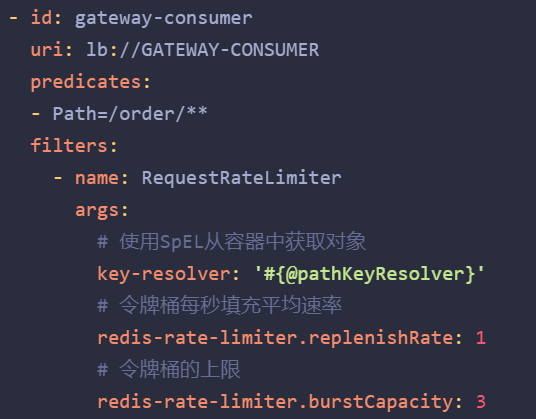

**补充整理示例：** 下面按课程时代的Gateway WebFlux配置结构书写，未部署。具体新版starter和属性前缀可能不同，应核对版本。

~~~yaml
spring:
  cloud:
    gateway:
      routes:
        - id: order-api
          uri: lb://order-service
          predicates:
            - Path=/orders/**
          filters:
            - name: RequestRateLimiter
              args:
                key-resolver: "#{@userKeyResolver}"
                redis-rate-limiter.replenishRate: 10
                redis-rate-limiter.burstCapacity: 20
                redis-rate-limiter.requestedTokens: 1
~~~

~~~java
// 假定鉴权过滤链已经建立可信Principal，省略导入
@Bean
public KeyResolver userKeyResolver() {
    return exchange -> exchange.getPrincipal().map(Principal::getName);
}
~~~

**参数理解：** 每秒补10令牌，容量20，每次消耗1，表示按此key允许一定短时突发，长期平均受补充速率约束。`requestedTokens`所在版本的支持情况需确认，不能忽略每个请求的成本。

key-resolver中的SpEL获取名为userKeyResolver的Bean；它不是把请求参数当作任意SpEL来执行。Principal为空时，应按产品规则拒绝、使用单独匿名配额或返回认证错误，并核对空key默认策略。

**课程路径key的局限：** 若直接使用含动态ID的原始路径，每个`/orders/123`、`/orders/456`都可能形成新key，用户可以通过变化路径绕过预期的统一配额。希望按接口总量限流时，可使用固定业务key或归一化路由模板；希望按用户时，使用可信用户标识。

**补充集群条件：** 常见RedisRateLimiter借助Redis与Lua完成相应令牌更新，多Gateway实例要正确共享Redis及一致的限流配置，才能形成相应共享配额。Redis连接失败时具体如何放行、拒绝或回退，必须核对所用版本并验证，不能凭“分布式限流”四字推断。

网关还应覆盖直达服务的内部入口或作相应访问控制。限流失败、Redis延迟和拒绝数量本身都需要监控。


## 19. CAP：网络分区时的取舍

**课件第29～33、35页、在线问答11～12：** CAP包含一致性、可用性与分区容错，发生网络分区时C和A无法同时满足。

| 术语 | 补充更准确的理解 |
|---|---|
| C，Consistency | CAP常用形式中的线性一致性，操作效果应符合实时顺序下的单份数据语义 |
| A，Availability | 对非故障节点的请求最终完成并给出有效结果，不靠统一拒绝来满足 |
| P，Partition tolerance | 即使节点间部分通信丢失或无限延迟，仍需要按系统选择的语义处理请求 |

“不同节点随时看见的值相同”是课程直观解释，线性一致性还涉及读写发生顺序。CAP中的C也不同于数据库ACID里的Consistency，后者主要指事务保持约束和业务规则。

**补充账户副本例子：** A、B网络断开，A收到把余额从100改为80的写入。B随后收到读取，无法确认A的新值。

- B继续返回旧值100，可能满足服务请求的可用性，但破坏要求的线性一致性。
- B等待通信或拒绝读取，以免返回未经确认的数据，则不能保证该请求的CAP可用性。

这是分区情形下的矛盾。正常联网时系统可以在很多操作上兼顾一致性和可用性，还存在延迟、成本等取舍。CAP不是“平时随便三选二”，也不是所有功能永久只能贴一个CP或AP标签。

**CP取向的实际表现：** 分区时可能只有获得多数派的一侧继续工作，另一侧拒绝相应操作。这不意味着整个系统所有功能完全停止。

**历史修正：** 课件给出的“1998年提出”不是适合死背的可靠年份。通常资料将Brewer的公开猜想记为2000年、Gilbert与Lynch的形式化证明记为2002年。本篇重点是理论条件，没有逐项进行历史文献核验。


## 20. BASE与最终一致性的实现条件

**课件第34～35页、在线问答13：**

| BASE | 含义 | 业务示例 |
|---|---|---|
| Basically Available，基本可用 | 故障时保留核心能力，允许部分功能受限 | 订单查询可用，部分推荐暂停 |
| Soft State，软状态 | 允许一定时间的中间状态 | 订单显示“支付确认中” |
| Eventually Consistent，最终一致 | 在规定条件下，通过同步或恢复最终收敛 | 支付事件重试后订单更新为已支付 |

**补充条件：** 最终一致不会自动发生。要能可靠记录状态变化、重试未完成操作、识别重复、处理失败，并在无法自动恢复时对账或介入。若消息永久丢失、补偿一直失败或状态持续相互覆盖，系统可能永远不收敛。

状态可以异步更新，但需要定义收敛目标和最长允许时间。用户看到“处理中”时，应能查询、超时处理或得到明确结果，不能一直停留在没有恢复途径的中间状态。

**课件例子：** 订单成功、扣款成功而库存不足，说明跨服务操作可能部分完成。恢复可以按业务撤销扣款、关闭订单，也可采用事先预留资源等方案；不能把数据库值简单恢复就假定外部付款已经退回。

**修正：** BASE是设计思想，不能作为某套事务框架的完整保证；“先提交分支再补偿就是AP，等所有分支再提交就是CP”也只是粗略类比。分布式事务的原子提交、隔离和CAP取舍要分别分析。

**面试回答：** 说明业务允许哪些中间状态，状态怎样被持久记录，失败怎样重试/补偿，重复怎样处理，以及通过什么机制证明最终结果已收敛。


## 21. 分布式事务的业务边界与Seata角色

**课件第36～37页、在线问答14：** 跨服务写入可考虑Seata或消息方案。Seata有TC、TM和RM三个重要角色。

| 角色 | 职责 |
|---|---|
| TM，Transaction Manager | 定义全局事务范围，发起并结束全局事务 |
| RM，Resource Manager | 管理分支资源，注册分支、报告状态并执行提交/回滚等动作 |
| TC，Transaction Coordinator | 管理全局和分支事务状态，协调最终决定 |

**补充XID：** 全局事务需要一个标识；调用链各参与方必须正确传播相应上下文，RM才能将分支归属到同一全局事务。仅在入口加注解，但远程上下文丢失、数据源未按要求接入或异常被吞掉，都可能使方案失效。

**概念区分：** Spring的本地`@Transactional`通常只管理所配置事务管理器对应的资源，不会自动把另一个服务的数据库纳入事务。远程HTTP成功也不证明整个业务已经原子提交。

**选择先问业务：** 要保护什么不变量，例如付款不能重复扣、库存不能变负、订单与账务最终能够对账。再判断是否允许异步处理、中间状态、回退，以及外部系统是否支持资源预留或补偿。

课件“多个服务有写操作都需要分布式事务控制”过于绝对。需要保证的是跨服务业务一致性；可能通过重新划分聚合边界、可靠事件、状态机、对账等实现，也可能确实需要协调事务。无相关业务约束的两个写入不必强行绑成一个全局事务。

**补充Seata注解示意，未执行：**

~~~java
@GlobalTransactional
public void createOrder(CreateOrderCommand command) {
    // 正确传播XID，调用参与全局事务的服务
    // 异常传播与回滚条件需按实际事务配置处理
}
~~~

注解本身不能撤回发送到任意外部系统的邮件、HTTP支付或文件写入。参与资源的能力和补偿范围必须明确。


## 22. XA：资源管理器参与的两阶段提交

**课件第38、42页：** 第一阶段执行分支业务但不最终提交；TC收集状态，第二阶段协调提交或回滚。

**补充两阶段过程：**

1. TM开启全局事务，各RM使资源参与相应XA分支。
2. 第一阶段执行SQL并进入prepare等准备状态，数据库按XA协议保持相关事务资源，向协调方报告结果。
3. 协调方确定全局结果，通知各分支commit或rollback。
4. 分支按决定完成处理；未完成的阶段需要恢复与重试，不能因一次网络超时就丢掉协调决定。

| 优点 | 代价或限制 |
|---|---|
| 利用数据库XA能力实现协调原子提交 | 数据库/驱动需要支持，资源兼容性要确认 |
| 应用较少手写反向SQL | prepare阶段可能长时间占用锁和连接 |
| 正常协议路径下有明确提交决定 | 协调方故障和结果未知需要恢复机制 |

**强一致说法的边界：** XA的主要目标是跨资源原子提交；端到端隔离级别、读路径和全局线性一致性仍需另外分析。原子提交不自动等于“所有节点随时的所有读取都看见一样的数据”。

“XA=CP”也不能作为严格推导。两阶段提交可能阻塞，说明它的可用性成本，但CAP分析仍需要给出分区情形、读写操作和所要求的一致性语义。

**失败追问：** 协调方发出提交后，某分支尚未确认结果，其他分支可能已完成提交；通常需要按记录的全局决定恢复，不能任意把已决定提交的部分改成回滚。运维需要观察悬挂事务、恢复记录与锁占用。


## 23. Seata AT：本地提交、Undo Log与全局锁

**课件第39、42页、在线问答14：** AT第一阶段执行业务并本地提交，记录数据快照；第二阶段提交可清理undo log，回滚则用undo log恢复。

**补充更完整过程：**

~~~text
第一阶段：
接入的RM解析支持的SQL，记录before image
执行业务SQL，获得after image，形成undo log
注册相关分支并申请全局锁等
将业务变更和undo log在同一本地事务中提交
报告分支状态

第二阶段提交：按协议完成状态及undo log清理，清理可异步
第二阶段回滚：读取undo log，校验当前数据与after image等
                按before image恢复，并处理日志和分支状态
~~~

课件中的步骤顺序是教学示意，实际拦截器、注册时机及代码路径随版本与资源实现变化。

| 日志/锁 | 作用 |
|---|---|
| before image | 记录业务更新前的相应数据 |
| after image | 记录更新后的相应数据，回滚时可据此检测不符合预期的改动 |
| undo_log | 与本地业务写入共同提交，为之后恢复提供依据 |
| 数据库本地锁 | 在本地事务期间保护数据库并发访问 |
| Seata全局锁 | 协调参与AT协议的相关写入，范围和冲突处理由协议决定 |

**关键边界：** 本地事务已提交，所以数据库普通查询可能看到全局事务尚未决定的中间结果。全局锁不能强制所有普通读和未接入Seata的外部写入都按全局隔离规则运行；需要按实际读写模式和全局锁机制设计。

若其他写入改变了after image对应的数据，不能不检查就直接用旧快照覆盖，否则可能误删合法变更。回滚失败、脏写检测和人工介入是需要观察的异常路径。

AT减少了XA那类长期数据库锁占用，但仍有全局锁、日志开销、支持SQL范围、数据源代理和回滚成本。不能概括成“AP所以永远高可用”，也不能说“有undo log就全部自动成功回滚”。

**面试回答：** AT先把业务数据和undo log本地提交，第二阶段提交清理日志，回滚基于快照和校验恢复；它通过相应全局锁协调参与写入，但普通读取和协议外写入的隔离边界必须明确。


## 24. TCC：业务资源预留与三类异常

**课件第40、42页：** Try检测并预留资源，Confirm完成操作，Cancel释放预留资源，需要应用编写相应业务逻辑。

**补充账户示例：** 扣30元前余额100元。Try将可用余额改为70、冻结30；Confirm消耗冻结的30；Cancel释放冻结并恢复可用余额100。这样第二阶段操作的资源在Try时已经准备好，具体账户模型和账务记录仍要按业务设计。

| 阶段 | 持久状态与动作 | 重复执行要求 |
|---|---|---|
| Try | 校验、预留，记下全局/分支业务标识和TRY状态 | 同标识不能再次冻结 |
| Confirm | 对已预留资源确认，转CONFIRMED | 已确认返回确定结果，不能再次扣款 |
| Cancel | 释放预留，转CANCELLED | 已取消不再次退款/解冻 |

**必须处理的三类问题（补充）：**

- **幂等：** Confirm/Cancel可能因网络和协调重试而执行多次，用持久业务状态、唯一约束和条件更新保证只生效一次。
- **空回滚：** Cancel到达时Try可能根本没有执行。应安全记录取消结果或按协议处理，不能无依据给余额加钱。
- **悬挂：** Cancel已经完成，迟到的Try才开始。应通过防悬挂记录/屏障检查拒绝预留，否则资源冻结后可能再也收不到取消。

这些检查和资源变化应放在相应本地事务内，并确保并发状态转换互斥，避免“先查后改”的竞争。可以使用框架提供的防护能力，但需要核对确切模式和版本支持，不能只靠注解名称判断。

课件“Try成功，Confirm一定成功”表达的是设计目标：Try应完成必要检查与预留，Confirm应足够简单并可重试。网络、数据库故障仍会使一次Confirm调用失败，系统需要恢复机制才能完成最终结果。

**选型：** TCC适合可明确预留和释放资源的业务，应用侵入与开发维护成本较高。对不可逆外部操作，要有真正可执行的业务补偿；“写一个反向方法”不证明现实世界结果可撤销。


## 25. 消息方案：Outbox与消费幂等

**课件第41～42页：** 用借款申请与到账展示异步执行、本地事务和消息。课程图写“生成借款单和发MQ在同一事务”。

**关键修正：** 普通数据库事务无法自动原子控制任意MQ发送。`@Transactional`中写库再`send()`，仍可能出现写库成功、消息没发出，或消息已发出、数据库回滚。生产者confirm能证明相应投递确认，也不等于数据库与MQ跨资源原子提交。

**补充一种可靠落地方式：本地消息表/Outbox。**

1. 服务A在同一本地数据库事务中写业务记录，并插入带稳定event_id的Outbox记录。
2. 提交后，由可靠发布器扫描或通过相应CDC机制发布事件。
3. 确认消息到达预期持久化节点后，再更新投递状态；失败记录保留并有界重试。
4. 服务B消费消息，在自己的本地事务中写去重记录并完成业务变更。
5. 本地事务提交成功后按所用MQ客户端方式确认消费，失败则允许后续恢复。
6. 长期失败进入告警、死信/人工处理及业务对账路径。

~~~text
A数据库：业务数据 + outbox(event_id, payload, state)
                     同一本地事务
           发布器重试
MQ：       可能重复投递，保留稳定event_id
B数据库：去重记录(event_id唯一) + 业务变更
                     同一本地事务
~~~

发布成功后、标记已发送前进程崩溃，会再次发消息，因此消费者必须幂等。消费者业务提交后、ACK前崩溃，也会重新投递，仍须使用同一事件ID识别重复。

**事件顺序补充：** 同一订单“支付成功”“退款成功”不能因乱序让状态倒退。可以使用业务版本、允许的状态转换、按业务key有序处理等方式，具体实现与MQ能力有关。

MQ事务消息是另一类机制，需要对应产品能力、本地事务状态检查和消息恢复。不能把所有MQ都理解成支持同一种事务消息。RabbitMQ/Kafka详细可靠性在06消息中间件篇展开。

**方案比较：**

| 方案 | 核心机制 | 主要关注 |
|---|---|---|
| XA | 资源准备后协调最终提交 | 支持范围、锁与连接、故障恢复 |
| AT | 本地提交业务和undo log，协调锁与补偿回滚 | 中间可见性、全局锁、脏写与SQL范围 |
| TCC | 业务预留后确认或取消 | 侵入、幂等、空回滚与悬挂 |
| 可靠事件 | 本地持久记录事件并异步恢复 | 重复、乱序、延迟、对账与补偿 |

不存在不看场景就固定成立的“MQ性能最好、XA只能银行、AT只能互联网”排序。应比较同业务语义下的延迟、吞吐、恢复成本与资源占用。


## 26. 接口幂等的定义、场景与HTTP语义

**课件第43～44、47页、在线问答15：** 用户重复点击、MQ重复消息、应用超时重试都可能使同一业务执行多次。幂等用于保证重复执行不会重复产生预期业务副作用。

**定义修正：** 幂等关注“相同业务操作执行一次与重复执行，预期效果相同”。第一次调用可以改变状态，响应码、时间和日志也可能不同，不应解释成“每次调用完全不改变状态”或“返回值字节必须一模一样”。

| HTTP方法 | 规范语义 | 应用实现责任 |
|---|---|---|
| GET | 安全且幂等的获取操作 | 不能把扣款等副作用隐藏在查询接口里 |
| PUT | 幂等地创建/替换相应资源状态 | 用PUT做累加扣款会违背所声明的语义 |
| DELETE | 幂等地删除资源 | 第二次可能返回404，但资源最终状态仍相同 |
| POST | 不由规范默认保证幂等 | 可通过业务key和状态设计实现某个POST接口的幂等 |

**课件SQL示意：**

~~~sql
UPDATE t_item SET money = 500 WHERE id = 1;
UPDATE t_item SET money = money + 500 WHERE id = 1;
~~~

在没有其他写入的示例中，第一句绝对值赋值重复执行结果相同，第二句每次累加。并发覆盖、触发器、关联业务等仍需分析，不能仅凭SQL字面判断完整业务幂等。

**补充标识：** 要分清传输request_id和业务operation_id。客户端重试若每次生成新业务标识，服务端会认为是不同操作；只以“用户ID+商品ID”去重又可能误拦用户合法的第二次购买。

幂等key应带上业务类型与所属用户/租户，并与关键参数绑定。同key不同金额/收款方等应拒绝或按契约明确处理，而不能拿到第一次结果就误认为当前请求已完成。

**选择原则：** 数据库唯一约束防重复落库，持久幂等记录保存处理状态与结果，Token可减少重复提交，分布式锁可限制并发。它们承担的职责不同，需要围绕业务不变量组合。


## 27. 数据库唯一约束与持久幂等记录

**课件第44、47页：** 对新增业务可用唯一索引防止重复插入。

**补充订单示例，未执行：**

~~~sql
CREATE TABLE order_operation (
    id BIGINT PRIMARY KEY,
    tenant_id BIGINT NOT NULL,
    user_id BIGINT NOT NULL,
    biz_type VARCHAR(32) NOT NULL,
    operation_id VARCHAR(64) NOT NULL,
    request_hash VARCHAR(64) NOT NULL,
    state VARCHAR(16) NOT NULL,
    order_id BIGINT,
    UNIQUE KEY uk_operation (tenant_id, user_id, biz_type, operation_id)
);
~~~

真实业务表也可以对相应订单业务号建立唯一约束。标识字段应按模型正确处理NULL、规范化和字符比较规则，避免实际约束范围与预期不一致。

**本地事务内的设计示意：**

1. 验证当前用户与请求参数，计算规范化后的参数摘要。
2. 尝试插入幂等记录，依靠唯一约束获得该业务操作的处理权。
3. 在同一本地事务内进行订单写入、必要的条件更新，记录最终order_id和状态。
4. 提交成功后返回结果；重复请求用同key读取并返回已提交结果。
5. 若同key绑定的参数摘要不同，按契约报冲突，而不是执行另一份业务。

先查询不存在再插入，两个线程都可能读到不存在，必须由唯一约束等原子机制兜底。发生唯一冲突后的查询和异常处理要正确处理事务状态；不能在已标记回滚的事务里吞掉异常继续假定提交成功。

**结果未知：** 请求超时但数据库已经提交，再次调用返回原order_id，不再新建订单。若本地事务未提交就失败，业务与幂等记录应按相应事务一起回滚，允许后续重新处理。

需要长期显示IN_PROGRESS时，状态记录的提交与实际业务事务可能分开，因此必须补充超时恢复和所有权判断。这不同于上述“一次本地事务一起完成”的简单模式。

**外部副作用：** 数据库唯一约束只能保护参与同一设计的数据库结果。调用外部支付时，还需要对方支持稳定支付流水号、结果查询或相应可靠流程，不能以本地INSERT成功就宣布外部扣款幂等。

消费MQ时，同理把event_id去重记录和业务变更放在同一本地事务中，提交后再确认消息。仅先保存去重标记、后写业务，会在进程崩溃时吞掉尚未完成的操作。


## 28. Token加Redis：原子消费与业务恢复

**课件第45、47页：** 先生成Token存入Redis并返回前端，提交请求带Token，服务端验证后删除，拒绝重复提交。

**必须修正的竞争：** `GET`验证与`DEL`分两步时，两个并发请求可能都验证成功。应通过Lua等原子执行相应校验和删除。支持的Redis版本也可使用GETDEL，但涉及用户和参数绑定时仍需设计校验。

**补充Lua片段，未运行：**

~~~lua
-- KEYS[1]为业务Token key
-- ARGV[1]为服务端根据可信用户和规范参数计算的绑定值
local value = redis.call('GET', KEYS[1])
if value and value == ARGV[1] then
    redis.call('DEL', KEYS[1])
    return 1
end
return 0
~~~

返回1只表示这次原子校验并消费Token成功，不表示订单或支付已经提交。

**消费Token与数据库之间的空隙：** Token删掉后服务崩溃、数据库写入失败或响应丢失，重试发现Token不存在，却无法知道业务到底有没有执行。Redis脚本只能保证Redis内相应操作的原子性，不能顺带原子提交另一个数据库。

所以一次性Token更适合前端防重复提交等入口控制；要求可恢复业务幂等时，仍需要稳定业务operation_id、数据库状态/结果记录和查询机制。两者可以组合，不能把“Token不存在”统一当作“业务已成功”。

| 设计点 | 原因 |
|---|---|
| 随机性和合理TTL | 降低猜测并清理未消费Token |
| 绑定用户、业务与参数 | 防止跨用户或跨业务挪用 |
| 原子校验和消费 | 防止同时通过验证 |
| 持久业务结果 | 支持超时查询和安全重试 |
| 明确失败恢复 | 区分业务失败、处理中和已完成 |

前端禁用按钮也只能改善体验，网络重试、多个标签页或恶意请求仍会绕过前端约束。服务端和数据库必须保证核心结果。


## 29. 分布式锁与幂等：课件代码修正

**课件第46～47页：** 用Redisson锁限制下单并发，强调锁粒度与快速失败。

**课件代码问题：** 获取失败也进入finally执行`unlock()`，可能释放未持有的锁并抛异常；`tryLock(10, TimeUnit.SECONDS)`是两个参数的等待时间重载，不同时表示等待时间和固定自动释放时间，而且最多等10秒不等于立即快速失败。

**补充整理示例，未编译/执行：**

~~~java
public OrderResult createOrder(CreateOrderCommand cmd)
        throws InterruptedException {
    // 校验后的用户/租户和稳定operationId共同确定粒度
    String lockKey = "order:" + cmd.tenantId() + ":"
            + cmd.userId() + ":" + cmd.operationId();
    RLock lock = redissonClient.getLock(lockKey);

    if (!lock.tryLock(0, TimeUnit.SECONDS)) {
        throw new BusyException("同一操作正在处理，请查询或稍后重试");
    }
    try {
        // 调用另一个Bean的事务方法，提交业务结果并持久去重
        return orderTxService.createOnce(cmd);
    } finally {
        if (lock.isHeldByCurrentThread()) {
            lock.unlock();
        }
    }
}
~~~

DTO访问器、结果类型和事务方法是补充示意。两个参数重载没有显式leaseTime，在相应Redisson实现下通常使用watchdog续期；具体行为应核对客户端版本。显式`tryLock(waitTime, leaseTime, unit)`则涉及固定租期，业务超时可能使锁提前失效。

**关键区别：** 锁负责互斥。第一次订单创建完成、释放锁后，同一请求再次成功拿锁，若没有查已完成状态仍会创建第二个订单。因此锁本身不能构成完整业务幂等，持久唯一约束与状态检查仍必要。

锁key过大，如全站共用`heimalock`，会把无关订单串行化；过细则可能不能保护真正共享的库存/账户资源。下单幂等锁、库存并发控制和数据库事务保护的对象也可能不同。

**租期与恢复边界：** watchdog不能绝对防止长暂停、网络故障和锁服务失效造成互斥丢失。高价值写入需要持久业务约束，必要时用资源侧能校验的fencing token等机制。finally中检查持有状态可减少错误解锁，却不能撤回锁失效期间已发生的并发业务写入。

事务提交应覆盖业务结果；如果锁在事务真正提交前已释放，其他请求可能读不到已完成结果而重复进入。示例用独立事务Bean先返回已完成的事务结果，再释放锁，以说明时序要求。


## 30. XXL-JOB架构与十种路由策略

**课件第48～49、52页、在线问答16：** 调度系统用于集中管理计划任务、执行日志、重试和大任务分片。直接在多个服务副本中运行相同本地定时任务，可能重复处理同一批数据。

**补充架构：** 调度中心管理任务定义和触发，将任务路由到注册的执行器；执行器运行对应JobHandler并记录或回报结果。JobHandler名称要与管理界面配置匹配，执行器地址要能被调度中心访问。

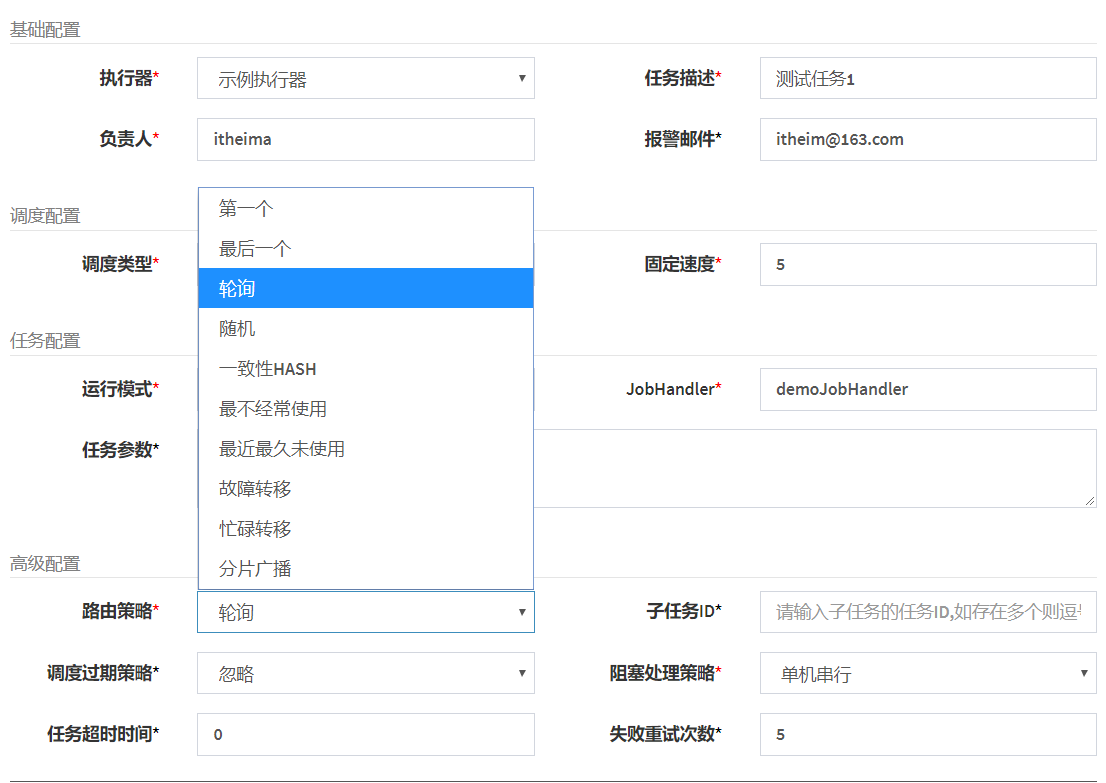

| 路由策略 | 主要行为 | 边界 |
|---|---|---|
| FIRST | 固定选择列表第一个 | 实例列表变化可能改变目标 |
| LAST | 固定选择最后一个 | 同上 |
| ROUND | 轮询 | 不是按实时CPU负载均衡 |
| RANDOM | 随机 | 不保证短期绝对均匀 |
| CONSISTENT_HASH | 按任务key等作一致性哈希路由 | 不是自动对任务内每条数据分片 |
| LEAST_FREQUENTLY_USED | 按路由使用频度选较少使用的 | 指相应路由统计，不等于机器CPU最低 |
| LEAST_RECENTLY_USED | 选较久未使用的 | 也不是资源利用率探测 |
| FAILOVER | 按顺序探测，选第一个可达执行器 | 不自动迁移正在执行任务的内存进度 |
| BUSYOVER | 按相应空闲探测选执行器 | 忙闲判断范围与版本/任务上下文有关 |
| SHARDING_BROADCAST | 广播给相关执行器并传递分片参数 | 应用代码必须按参数筛选数据 |

**路由与阻塞策略不同：** 路由决定发给哪台执行器；单机串行、丢弃后续、覆盖之前等阻塞处理策略决定任务在相应执行上下文重叠时怎样处理。不能把“单机串行”说成整个集群业务永远只执行一次。

**补充调度表达式：** 在支持相应Cron语义的配置中，`0 */5 * * * ?`通常表示每5分钟第0秒触发。XXL-JOB版本和调度类型需核对，不能直接按Linux五字段cron解释；错过执行时如何处理也需明确。

即使中心化调度通常避免对同一普通任务广播给所有实例，网络超时、重试和人工重触发仍可能重复执行。业务幂等与恢复机制不能省略。


## 31. XXL-JOB失败处理、日志与结果未知

**课件第50、52页、在线问答17：** 使用故障转移、失败重试、日志和邮件告警。课件邮件截图具体失败原因为**执行器地址为空**，失败重试次数示例是5次，这些属于教学配置。

| 故障阶段 | 首先检查 | 后续动作 |
|---|---|---|
| 没有可用执行器 | 注册方式、AppName、地址、网络、访问凭据 | 修复注册与连通性，别先改业务算法 |
| 请求调度失败 | 中心至执行器网络、接口、超时与配置 | 判断是否可能实际已接收，再作可控重试 |
| Handler执行失败 | 执行日志、异常、参数、数据库/外部依赖 | 修复原因，确认已完成的部分 |
| 执行超时 | 慢查询、阻塞、循环和资源饱和 | 超时中断不一定撤回数据库或外部副作用 |
| 回调失败/结果未知 | 执行器与中心的结果上报 | 查业务状态和执行日志，避免盲目重做 |
| 长期失败 | 重试消耗、失败原因和业务积压 | 告警、隔离异常数据、对账与人工处置 |

**故障转移的准确含义：** FAILOVER通常在路由时尝试选择可用执行器；某执行器开始运行后突然故障，系统不能仅靠换一台机器就知道已经处理到哪条记录。重试要从持久进度或可幂等的业务状态继续。

**补充日志：** 关联任务ID、调度日志ID、执行器、业务批次、分片、处理数量与关键业务ID。既看调度日志，也看执行日志与业务库结果；“调度成功”不等于每一条业务处理成功。

**失败报告：** 按对应版本的Handler约定抛出异常或报告失败。把异常吞掉后正常返回，可能使中心误判成功。批处理若部分失败，需要明确是整批失败、部分成功还是另行记录失败项。

**重试设计：** 只对可重试故障重试，次数有界，必要时安排退避，避免所有实例同时冲击下游。扣款、发券、外部通知等需要稳定业务标识和结果查询。

告警信息应说明任务、环境、失败阶段和处理入口。这里只记录告警设计，没有修改调度平台或发送邮件。


## 32. 分片广播、数据筛选与大批量任务

**课件第51～52页、在线问答18：** 选择分片广播后，每个执行器都收到一次触发。通过`getShardIndex()`与`getShardTotal()`获取当前分片和总数，按取模分配数据。

**课件例子：** total=3，正整数业务ID按`id % 3`归属分片0、1、2。例如1、4、7归分片1，2、5、8归分片2，3、6、9归分片0。

**补充Handler片段，未编译/运行：**

~~~java
@XxlJob("closeExpiredOrders")
public void closeExpiredOrders() {
    int index = XxlJobHelper.getShardIndex();
    int total = XxlJobHelper.getShardTotal();
    if (total <= 0 || index < 0 || index >= total) {
        throw new IllegalArgumentException("非法分片参数");
    }
    // 学习接口：共享同一批次截止时间，按分片在数据库侧分页
    // 每条记录用事务和条件状态更新保证重复执行安全
    orderBatchService.closeDueOrdersForShard(
            XxlJobHelper.getJobParam(), index, total, 500);
}
~~~

示意中500是学习批大小，不是测出的最优值。repository、状态机与批次参数解析没有在此实现。

**补充分页思路：**

~~~sql
-- 示例假定id为非负、具有相应索引和业务条件
SELECT id
FROM orders
WHERE status = 'UNPAID'
  AND expire_at < :batch_cutoff
  AND id > :last_id
  AND MOD(id, :shard_total) = :shard_index
ORDER BY id
LIMIT :batch_size;
~~~

该SQL是逻辑示意，命名参数由数据访问框架绑定；MOD可能不利于索引访问，实际大表要分析执行计划并考虑范围分片、任务表或预计算分片列等。

**课件写法的规模边界：** 所有实例先把全部任务读进内存，再循环取模过滤，虽说明了原理，却会放大数据库读取与内存占用。较大数据量应尽早在查询/领取阶段筛选、分页并记录进度。

**并发安全：** 关单可使用预期状态的条件更新，例如只把仍未支付的订单关掉；支付和关单竞争时，应按业务事务与锁/版本规则作出唯一合法转换。若已经支付，重复关单不应把状态改回。

分片总数变化会重新分配ID，调度重叠或旧执行器未结束也可能重复处理。同一批次的分片视图与截止时间应明确，并用持久状态/唯一约束/任务领取机制防重。分片广播不保证exactly-once，也不自动检查是否遗漏数据。

**补充运行方案：** 限制每批量与执行时间，记录游标和失败项，对重试次数耗尽的数据作隔离/告警，通过对账统计应处理、成功、失败和剩余数。数据倾斜严重时再调整分片方式，而不是只增加实例。


## 33. 综合学习案例：下单、库存与超时关闭

以下是**补充设计练习**，用于把本篇概念连起来，不是课件完整项目实现，也不是个人项目经历。

**场景：** 用户创建订单，库存服务预留库存，支付结果异步返回，超时未付款需要关闭。允许订单短时处于“库存确认中”，但不能重复下单、扣负库存或关闭已支付订单。

| 环节 | 设计关注 |
|---|---|
| Gateway入口 | 可信用户/路由配额，拒绝后给出可理解结果 |
| 服务调用 | 发现健康实例并选择，超时和结果未知时按约定处理 |
| 创建订单 | 稳定operation_id与唯一约束，同一本地事务记录订单和Outbox |
| 请求库存 | 带稳定event_id、订单号、业务版本和所需数量 |
| 库存处理 | 去重记录、条件扣减/预留与事件记录在相应本地事务内 |
| 状态回传 | 可靠发布库存结果，订单只接受合法且匹配版本的转换 |
| 支付处理 | 稳定支付流水，回调去重，向外部支付方查询未知结果 |
| 超时关闭 | XXL-JOB分片分页，按当前业务状态及支付规则条件更新 |
| 释放库存 | 关闭事件可靠投递，释放动作幂等，防重复加回库存 |
| 观察与恢复 | Trace定位、错误指标、任务积压、Outbox与业务对账 |

**迟到事件：** 订单已经关闭后库存预留才成功，不能简单把订单恢复成可支付；应按状态机拒绝错误转换，并可靠地产生释放资源等补偿动作。预留成功、取消、支付回调乱序时，需要规定唯一允许的最终状态与处理优先级。

**事务选型：** 上表采用可靠事件与持久状态恢复的思路。若业务要求更强的同步预留语义，可另行评估TCC或合适的协调事务方案。不要把XA、AT、TCC全部叠加，再把每条SQL同时解释成多种协议。

**故障演练思路：**

1. 创建事务提交后丢失响应，再次使用同operation_id应得到原订单。
2. Outbox发布后、标记前崩溃，消费重复事件仍只产生一次库存变化。
3. 库存事件晚于关闭事件，状态机最终正确释放预留。
4. 关闭任务执行到一半失败，重跑只处理仍满足条件的订单。
5. 支付与关闭并发，按明确的支付确认规则、状态更新和补偿流程收敛。

这些是待验证的期望，不是已经跑过的测试结果。真实实现还应覆盖库存不足、外部支付异常、取消超时、事件乱序和人工对账流程。

**面试讲述模板：** 业务不变量、允许的中间状态、稳定标识、事务范围、失败恢复、监控与验证证据。只有亲自完成并能解释细节的部分，才应写成项目实践。


## 34. 十八题面试自测与练习清单

对应在线讲义的18组问题。先遮住答案自己口述，再检查是否说清机制和边界。

| 题目 | 回答要点 | 本篇位置 |
|---|---|---|
| 1. Spring Cloud五大组件 | 历史组合与职责，说明实际版本和新体系 | 1 |
| 2. 服务注册发现 | 注册、发现、缓存、实例选择、请求和健康检查 | 2 |
| 3. Nacos与Eureka | 注册发现共性，配置、更新、健康与版本差异 | 3 |
| 4. 负载均衡如何实现 | 发现实例列表，选择目标，HTTP客户端发送 | 4 |
| 5. Ribbon有哪些规则 | 七种规则与默认上下文，区别BestAvailable和AvailabilityFiltering | 5 |
| 6. 如何自定义规则 | IRule或新LoadBalancer扩展点，配置范围与健康过滤 | 6 |
| 7. 雪崩如何处理 | 下游慢导致资源耗尽，超时、隔离、熔断、降级和限流 | 7～9 |
| 8. 微服务怎样监控 | Agent/OAP/Storage/UI，Trace、指标、日志和告警 | 10～13 |
| 9. 项目如何限流 | 业务容量、维度、层次、拒绝与监控 | 14、16～18 |
| 10. 限流算法 | 漏桶平滑，令牌桶突发，窗口法补充与集群原子性 | 15 |
| 11. 什么是CAP | C的语义、A的有效响应、P的分区条件 | 19 |
| 12. 为什么C与A不能兼得 | 分区下无法确认远端写入，继续响应或等待的矛盾 | 19 |
| 13. 什么是BASE | 核心可用、中间状态、可靠恢复后收敛 | 20 |
| 14. 分布式事务方案 | TC/TM/RM，XA/AT/TCC和可靠事件的取舍 | 21～25 |
| 15. 接口幂等设计 | 稳定业务key、唯一约束、持久结果，Token和锁的边界 | 26～29 |
| 16. XXL-JOB路由 | 十种策略，路由与阻塞策略不同，广播需筛数据 | 30 |
| 17. 任务失败如何处理 | 定位失败阶段、结果未知、有界重试、日志与告警 | 31 |
| 18. 大量任务怎样执行 | 分片参数、查询侧筛选、分页、幂等和进度恢复 | 32 |

### 需要能解释的追问

- 注册中心不可用时，缓存能帮助哪些调用？什么场景仍然失败？
- 断路器打开后是否所有请求都定时重新访问下游？最低样本量为什么重要？
- 限流burst、并发上限、线程数之间为什么不能相互代替？
- AT本地提交后普通查询能否看见中间状态？协议外写入会影响什么？
- TCC先Cancel再Try会发生什么？资源与防悬挂状态如何一起提交？
- 消息发布成功后进程崩溃，为什么仍会重复投递？
- 删除Redis Token后数据库没提交，用户重试时怎样知道结果？
- 第二次拿到同一把锁，为什么仍可能重复创建订单？
- XXL-JOB执行器换一台，凭什么判断前一台已处理到哪条？
- 从3个分片扩到4个分片，对同一批数据的归属有什么影响？

### 建议练习，尚未执行

1. 用两个服务实例观察注册列表、缓存更新、超时与负载选择，记录实际版本及参数。
2. 在独立实验环境比较Nginx排队与nodelay，观察429、后端瞬时并发和延迟分布。
3. 为同一业务key发送并发与顺序重复请求，验证数据库只产生一个业务结果；测试同key不同参数。
4. 为Outbox发布和消费提交前后加入可控故障，检查恢复与去重。
5. 将分片任务在相同批次下重跑并模拟失败，核对成功、失败、剩余及重复副作用。

每次练习记录预期、实际结果、版本和配置。不使用未执行的练习去声称“已验证生产可靠性”。


## 35. 课件勘误、来源与覆盖范围

### 容易背错的结论

| 原资料表述或简化 | 本篇修正 |
|---|---|
| Feign底层一定是Ribbon | 这是旧集成，现代负载均衡要看依赖和配置 |
| 90秒没心跳一定立刻剔除 | 还受清理、自我保护和客户端缓存影响 |
| 持久实例让整个Nacos切成CP | 按实例类型、模块及版本分析一致性机制 |
| AvailabilityFiltering选连接最少 | 核心是过滤不可用/超过阈值候选后再选择 |
| Hystrix失败率50%就触发 | 还有最低请求量、窗口和启用条件 |
| SkyWalking instance就是物理机 | 应理解为服务运行实例，可为JVM/容器/Pod |
| 同服务多实例用不同service_name | 通常服务名相同，实例标识不同 |
| maxThreads是最大连接数 | 属工作线程容量，连接和队列另有参数 |
| limit_req_zone = ...用于启用限流 | 应使用limit_req zone=...，定义与应用分开 |
| burst或令牌容量就是并发量 | 突发额度与并发资源是不同维度 |
| XA/AT/TCC等于固定CP/AP标签 | 原子提交、隔离、分区行为需要分别讨论 |
| 写库和普通MQ send天然同事务 | 需要Outbox、相应事务消息或其他可靠协议 |
| Token存在先查再删就安全 | 原子消费仍不解决数据库事务与结果未知 |
| 分布式锁能保证接口幂等 | 还需要持久业务key、状态和唯一约束 |
| 获取锁失败也在finally unlock | 仅由成功持有者解锁，检查租期及提交时序 |
| FAILOVER保证失败任务完整迁移 | 路由选择与业务进度恢复是不同职责 |
| 分片广播自动防重复与遗漏 | 必须筛选、分页、恢复并维护业务幂等 |

以上修正已在对应章节解释。它们不是把旧课件全部否定，而是补足复制示例或口述答案时必须知道的条件。

### 来源

- [百度网盘分享](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)，提取码9987。
- 课件：`05-微服务篇/PPT/05-微服务篇.pptx`，53页；本机下载为`C:\Users\23224\Downloads\05-微服务篇.pptx`。
- [飞书《微服务篇》正文](https://heuqqdmbyk.feishu.cn/wiki/RQECwUZeLibCrokfQtxcTPk5nvg)，页面显示2024年8月29日修改，已读取18组问答，评论不作为技术依据。
- `在线讲义文稿.txt`全部内容只有[专题目录URL](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)。
- 配套`资料/skywalking/讲义/项目链路追踪.md`：通过网盘预览读取全部可用正文和源码结尾，共显示608行；采用8.2.0的配置示例，末尾实践步骤未完。

### PPT主题覆盖

| 课件页 | 主题 | 本篇对应 |
|---|---|---|
| 1～3、23 | 封面、主题路线和业务部分导航 | 导言与目录 |
| 4～10 | 组件、注册发现、Eureka与Nacos | 1～3 |
| 11～15 | Ribbon流程、规则与自定义 | 4～6 |
| 16～19 | 雪崩、降级与熔断 | 7～9 |
| 20～22 | 监控与SkyWalking | 10～13，并扩展配套讲义 |
| 24～28 | 容器、Nginx和Gateway限流 | 14～18 |
| 29～35 | CAP与BASE | 19～20 |
| 36～42 | Seata角色、XA/AT/TCC、消息方案 | 21～25 |
| 43～47 | 幂等、HTTP语义、Token与锁 | 26～29 |
| 48～52 | XXL-JOB路由、重试与分片 | 30～32 |
| 53 | 空白页 | 无正文可整理 |

### 视频与其他资料范围

11节视频标题分别是：课程介绍、常见组件、Eureka/Nacos注册中心、Ribbon规则与自定义、雪崩与熔断降级、SkyWalking、微服务限流、CAP/BASE、分布式事务、接口幂等、XXL-JOB。仅核对标题，未观看、未转写，无法保证覆盖老师口述补充。

配套PDF没有读取正文；assets中的图片未逐一打开，Markdown预览引用图片未加载；`skywalking/资料`中的运行资源未逐项读取或运行。PPT内嵌图片已经查看并选择3张嵌入本Notebook，与上述未加载的Markdown图片不同。

本篇仅生成学习笔记。所有示例未执行，未部署监控/网关/调度系统、导入SQL、调用支付或发送通知，未对课程项目性能、事务恢复或并发安全作实测结论。
